# Stopping model: time-varying bound, sensory noise, guesses, and lapses

**Status (2026-10-10, model version 2):** `pigeon/stopping.py` (tests in
`tests/test_stopping.py`). Focus: OL (blocks 1–6) and MX (blocks 1–3). Bound
level and variability and the guess, lapse and anticipation rates are per block;
the bound's time course, sensory noise and NDT are shared across a subject's
blocks. Anticipations are first-frame presses (RT = 1) only. Trials follow the paper's conventions. Fits
and recovery are run by scripts and cached in `data/processed/`. MXSC and the
change-point blocks come after OL and MX are settled.

## Why this notebook

Every bound analysis in the paper treats each trial as a bound crossing and handles
guessing only by filtering (`DT >= 2`, `trial_number >= 10`, the `rt_below_cutoff`
from `get_bounds`). This notebook fits an explicit trial-level model of *when*
subjects stop and *which* side they choose, so that guesses are estimated rather
than filtered.

**Why not accuracy or congruence.** With Gaussian steps of mean ±μ, the
likelihood ratio for "right" vs. "left" depends only on the current position `x`.
So for a subject who chooses the side the pigeon is on, P(correct | x at commit)
= logistic(2μ|x|/σ²), *whatever* rule decided when to stop. Accuracy (and
congruence) therefore cannot separate a low bound from evidence-independent
stopping; only the timing of commitments can. A bound-based rule and a
random-timing rule both give accuracy that rises with SNR and with commit time
(see `scratchpad/acc_policy.py` from the 2026-10-09 session).

## Task facts the model relies on

- Steps are Gaussian: `move_pigeon_function` in both `task/OL-MX-PD/PigeonTask.js`
  and `task/MXSC/PigeonTask.js` draws `step_mean + step_std * N(0, 1)` (Marsaglia
  polar method).
- `steps` records the *displayed* position, clamped at ±0.75 (`EDGE_DISTANCE`);
  the walk itself is not clamped. Once at the wall the pigeon stays at the edge
  until the key press, so a long RT after a wall hit says nothing about stopping.
  Wall hits are common in OL/MX (11–14% of trials) and rare in MXSC (49 trials).
- A response is possible on the trial's first frame, before any step (RT = 1):
  14% of OL trials, 11% of MX, 2% of MXSC. These are commits with no evidence
  (anticipations).
- Each position is shown for 200 ms (`UPDATE_INTERVAL = 0.2` in both task
  versions), so an NDT of n steps means the key press came 200·n to 200·(n+1) ms
  after the commit position appeared.
- **Datasets:** OL, MX and MXSC. Not PD: there the bound is set before the trial,
  so there is no voluntary stopping to model.

## Model (version 2)

Notation: `x_j` is the on-screen position after `j` steps (`x_0 = 0`).

1. **Anticipation.** With probability `a` the key is pressed during the trial's
   first frame (RT = 1), before anything shown could be processed; choice random.
   (Until 2026-10-10 anticipations were spread over the first NDT + 1 frames,
   which over-predicted RT = 1 and under-predicted RT = 2.)
2. **Bound.** The bound at step `j` is `b_j = m · θ(j)`. The trial's multiplier `m`
   is gamma-distributed with mean 1 and coefficient of variation `bound_cv`
   (trial-to-trial bound variability). The time course is
   `θ(j) = bound_scale · h(j)`, with `log h` piecewise linear through knots at
   steps 1, 6 and 16 (constant outside them) and `h(6) = 1`, so `bound_scale` is
   the mean bound at step 6 (about the median commit step, where the level is
   best determined). A penalty on each log change (prior SD 0.5) keeps the time
   course near flat unless the data say otherwise; with 33–150 trials per block,
   an unpenalized curve trades an extreme early bound against a steep collapse.
3. **Sensory noise.** The subject sees `y_j = x_j + e_j`, with independent
   `e_j ~ N(0, sensory_std²)`, and commits at the first `j ≥ 1` with `|y_j| ≥ b_j`,
   choosing the side crossed. This lets commits happen away from the pigeon's
   visible maximum and makes choices near the center noisy (the incongruence that
   Figure03S03 attributes to sensory noise).
4. **Guess.** If the bound isn't crossed at step `j`, the subject commits anyway
   with probability `g`, choosing the side of the perceived position. This
   includes step 0 (pigeon at center: random choice, RT = NDT + 1).
5. **Lapse.** With probability `ε` the choice is random (the incongruence floor at
   large bounds in Figure03S03, which noise can't produce).
6. **NDT** ∈ {1, 2} steps (200–600 ms from the commit position to the key press),
   probabilities fit per subject and shared across blocks. Longer delays aren't
   plausible as a sensorimotor latency; allowing them lets the model push commits
   back to the first step of short trials and infer implausibly low bounds.
   NDT 1–3 is kept only as a sensitivity check.

**Change-point blocks:** separate `bound_scale` (optionally `g`) for positions from
the change-point step on. Because the bound's time course is modeled, a bound that
falls over the trial is not mistaken for a post-change-point shift.

**Likelihood.** Given `m`, steps are independent, so each trial's likelihood is a
product over steps, integrated over `m` and averaged over NDT. The integral uses
Gauss–Legendre quadrature only over the window of `m` where that trial's
likelihood changes (below it the bound would have been crossed earlier; above it
only guesses can commit, in closed form). Exact without noise; within ~0.15
log-likelihood units of a 128-node reference otherwise.

**Wall-hit trials** answered later than any NDT allows (RT > wall step + 3) are
censored at the wall; all other trials use the ordinary likelihood.

**Trial selection** (`get_stopping_model_trials`): raw block numbering
(`combine_snr=False`; OL blocks 1–6, each a single SNR; MX blocks 1–3, mixed
SNR, the ones `combine_snr=True` keeps). A trial is dropped if
`trial_number < 10` or, for a subject with a good adaptation fit in that block
(`get_adaptation_tau_fits`, as in Figure04), `trial_number < ceil(τ)`; so the
effective cutoff is `max(10, ceil(τ))`. Trials without a choice (step budget ran
out) are dropped. No DT cutoff, no wall-hit exclusion, no bias correction.

**Which parameters are per block** (chosen by model comparison; see below).
`bound_scale`, `bound_cv`, `g`, `ε` and `a` are separate per block; the time
course (2 free knots), `sensory_std` and P(NDT = 1) are shared across a
subject's blocks. Free parameters per subject: 5 per block + 4 (OL: 34; MX: 19).

### Version 1 and why it was revised

Version 1 had a constant bound, no sensory noise and NDT 1–3. It fit the fixed
blocks well but only by attributing 20–67% of commits to "guesses", because any
commit not at the pigeon's farthest point so far had to be a guess. Figure03S03's
analysis (incongruence needs sensory noise; premature crossings need either NDT
> 2 or, as noted here, a bound that falls over the trial) and the implausibility
of NDT ≥ 3 at 200 ms per step led to version 2.

## Plan

1. **Implementation** (done): likelihood, simulator, fitter in `pigeon.stopping`, with tests.
2. **Recovery and mechanism attribution:** simulate at each dataset's trial counts;
   check parameter recovery, and that data generated by only guesses, only sensory
   noise, or only a collapsing bound are attributed to the right mechanism.
3. **Fixed blocks (OL, MX, MXSC Low/High):** fit; check against RT distributions,
   accuracy, and Figure03S03's incongruence and premature-crossing curves; compare
   variants (time course flat/shared/per block; NDT 1–2 vs 1–3; noise on/off) by
   held-out likelihood.
4. **How much guessing remains**, and how much survives the `DT >= 2` filter.
5. **Change-point blocks:** post − pre `bound_scale` within LowHigh and HighLow,
   with the time course accounted for, against simulated nulls.
6. **Decision:** whether guessing, noise or the bound's time course must be built
   into the bias correction, RR matrices and null models.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from pigeon.data import get_crossing_diagnostics, get_good_trial_array
from pigeon.stopping import (KNOTS, bound_time_course, get_stopping_model_trials,
                             infer_bounds_like_data, simulate_stopping_data_table)

PROCESSED = Path('../data/processed')

## Parameter recovery at OL and MX trial counts

From `scripts/run_stopping_recovery.py` (cached in `data/processed/stopping_recovery.pkl`).
Simulated subjects with each block's median real trial count after the exclusions
(OL: 111, 64, 33, 150, 121, 78; MX: 114, 92, 47) and step statistics (step SD
0.15; mean 0.05 or 0.15, mixed 50/50 within MX blocks), fit with the defaults.
True bound scale and CV and the guess, lapse and anticipation rates are drawn
per block; sensory noise, NDT and the time course (random log-linear) per subject.

converged: {'MX': 1.0, 'OL': 1.0}


parameter        anticipation_rate  bound_cv  bound_scale  guess_rate  \
task block                                                              
MX   B1 (n=114)               0.93      0.90         0.99        0.64   
     B2 (n=92)                0.81      0.65         0.98        0.48   
     B3 (n=47)                0.61      0.61         0.95        0.57   
     shared                    NaN       NaN          NaN         NaN   
OL   B1 (n=111)               0.86      0.76         0.97        0.45   
     B2 (n=64)                0.79      0.79         0.95        0.31   
     B3 (n=33)                0.51      0.67         0.94        0.45   
     B4 (n=150)               0.78      0.86         0.99        0.67   
     B5 (n=121)               0.87      0.68         0.95        0.49   
     B6 (n=78)                0.87      0.30         0.95       -0.09   
     shared                    NaN       NaN          NaN         NaN   

parameter        lapse_rate  log_h_first  log_h_last  ndt_p1  sensory_std  
task block                                                                 
MX   B1 (n=114)        0.34          NaN         NaN     NaN          NaN  
     B2 (n=92)         0.79          NaN         NaN     NaN          NaN  
     B3 (n=47)         0.31          NaN         NaN     NaN          NaN  
     shared             NaN         0.73        0.89    0.95         0.56  
OL   B1 (n=111)        0.65          NaN         NaN     NaN          NaN  
     B2 (n=64)         0.57          NaN         NaN     NaN          NaN  
     B3 (n=33)         0.53          NaN         NaN     NaN          NaN  
     B4 (n=150)        0.77          NaN         NaN     NaN          NaN  
     B5 (n=121)        0.63          NaN         NaN     NaN          NaN  
     B6 (n=78)         0.32          NaN         NaN     NaN          NaN  
     shared             NaN         0.75        0.77    0.96         0.89

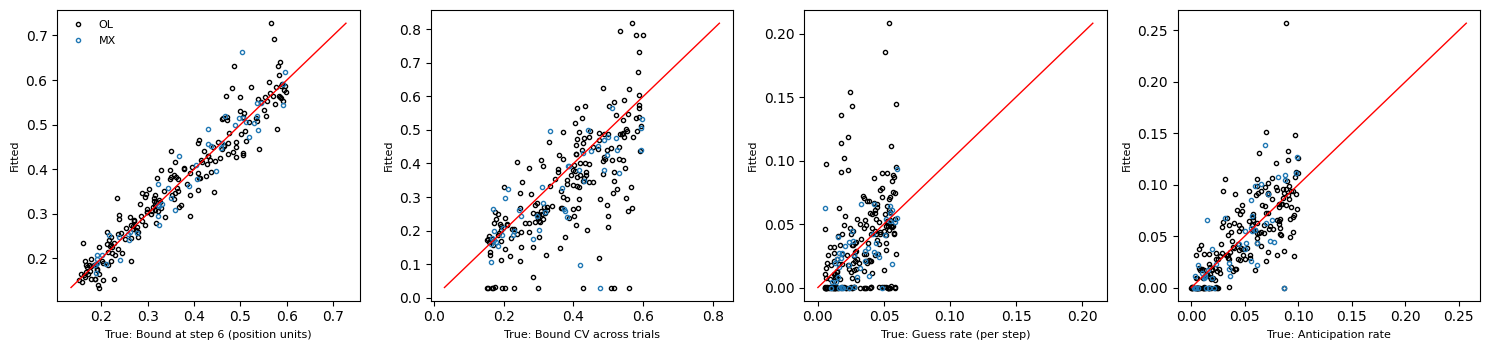

In [2]:
recovery = pd.read_pickle(PROCESSED / 'stopping_recovery.pkl')
print('converged:', recovery.groupby(['task', 'seed']).converged.first().groupby('task').mean().to_dict())

rows = []
for task, g in recovery.groupby('task'):
    s = g.groupby('seed').first()
    for k in ('sensory_std', 'ndt_p1', 'log_h_first', 'log_h_last'):
        rows.append({'task': task, 'block': 'shared', 'parameter': k, 'r': np.corrcoef(s[f'true_{k}'], s[f'fit_{k}'])[0, 1],
                     'median |error|': np.median(np.abs(s[f'fit_{k}'] - s[f'true_{k}']))})
    for b, gb in g.groupby('block'):
        for k in ('bound_scale', 'bound_cv', 'guess_rate', 'lapse_rate', 'anticipation_rate'):
            rows.append({'task': task, 'block': f'B{b} (n={gb.n_trials.median():.0f})', 'parameter': k,
                         'r': np.corrcoef(gb[f'true_{k}'], gb[f'fit_{k}'])[0, 1],
                         'median |error|': np.median(np.abs(gb[f'fit_{k}'] - gb[f'true_{k}']))})
rec_table = pd.DataFrame(rows)
display(rec_table.pivot_table(index=['task', 'block'], columns='parameter', values='r').round(2))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (k, label) in zip(axes, [('bound_scale', 'Bound at step 6 (position units)'), ('bound_cv', 'Bound CV across trials'),
                                 ('guess_rate', 'Guess rate (per step)'), ('anticipation_rate', 'Anticipation rate')]):
    for task, color in (('OL', 'k'), ('MX', 'tab:blue')):
        g = recovery[recovery.task == task]
        ax.plot(g[f'true_{k}'], g[f'fit_{k}'], 'o', mfc='none', color=color, ms=3, label=task)
    lims = [recovery[[f'true_{k}', f'fit_{k}']].min().min(), recovery[[f'true_{k}', f'fit_{k}']].max().max()]
    ax.plot(lims, lims, 'r-', lw=1)
    ax.set_xlabel(f'True: {label}', fontsize=8)
    ax.set_ylabel('Fitted', fontsize=8)
axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

**Recovery (2026-10-10, current defaults).** All 48 fits converged. Each block's
bound level recovers very well (r = 0.94–0.99, including the 33-trial OL block);
bound CV moderately (0.6–0.9, except OL B6 0.30). The shared time course
(r = 0.73–0.89) and NDT (0.95–0.96) recover well; sensory noise well in OL (0.89),
less in MX (0.56). **Per-block guess rates recover poorly** (r = −0.09 to 0.67)
and lapse rates moderately (0.31–0.79); anticipation rates well (0.51–0.93). So
interpret guess and lapse rates at the group level, not per subject and block.

An earlier recovery run (MXSC counts, time course shared) checked mechanism
attribution: data generated by only guesses, only sensory noise, or only a
collapsing bound were each attributed to the right mechanism (guess-only data gave
a small spurious collapse, about −0.06 in log h at step 6).

## Fits to OL and MX

Fits come from `scripts/run_stopping_fits.py` (cached in
`data/processed/stopping_fits_<variant>.pkl`). Main variant: bound scale and CV,
guess, lapse and anticipation rates per block; the bound's time course, sensory
noise and NDT {1, 2} shared across a subject's blocks. Variants for comparison:
`per_block_tc` (time course per block), `flat` (no time course),
`shared_rates` (guess, lapse and anticipation shared across blocks), `ndt123`
(NDT 1–3), `no_noise` (sensory noise fixed at 0).

**Why this split (round 1, 2026-10-09).** A first round with bound parameters
(including the time course) per block and the three rates shared found, by AIC
summed over subjects: rates per block much better (ΔAIC −12,039 OL, −1,007 MX;
e.g. 33% of OL block-4 responses at RT = 1 vs. a much lower rate in blocks 2–3);
one time-course shape per subject better than per-block shapes (−846 OL, −398 MX);
a constant bound worse (+2,382, +903); no sensory noise worse (+1,975, +453); NDT
1–3 worse than 1–2 (+203, +252). Round-1 fits are archived in
`data/processed/stopping_fits_round1/`.

In [3]:
DATASETS = {'OL': [1, 2, 3, 4, 5, 6], 'MX': [1, 2, 3]}
tables = {task: get_stopping_model_trials(task, blocks) for task, blocks in DATASETS.items()}
VARIANT_NAMES = ['main', 'per_block_tc', 'flat', 'shared_rates', 'ndt123', 'no_noise']
fits_all = {v: pd.read_pickle(PROCESSED / f'stopping_fits_{v}.pkl')
            for v in VARIANT_NAMES if (PROCESSED / f'stopping_fits_{v}.pkl').exists()}
fits = fits_all['main']
by_subj = fits.groupby(['task', 'subject_index']).first()
print('variants available:', list(fits_all))
print('main: fits that did not converge, by task:', (~by_subj.success).groupby('task').sum().to_dict(),
      '| fits that raised:', int(by_subj.error.notna().sum()))

OL: subjects with a good adaptation tau fit, by block: {1: 2, 2: 25, 3: 9, 4: 18, 5: 8, 6: 9}
OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 225 more in the adaptation transient, 364 more with no choice; 60 subjects


MX: subjects with a good adaptation tau fit, by block: {1: 3, 2: 15, 3: 11}
MX: 18,726 trials in blocks [1, 2, 3]; excluded 1,620 with trial_number < 10, 58 more in the adaptation transient, 182 more with no choice; 60 subjects
variants available: ['main', 'per_block_tc', 'flat', 'shared_rates', 'ndt123', 'no_noise']
main: fits that did not converge, by task: {'MX': 0, 'OL': 0} | fits that raised: 0


### Parameter estimates (main variant)

Median [interquartile range] across subjects. Per-block parameters: bound
level and CV and the guess, lapse and anticipation rates (`bound_scale` = mean bound at step 6, in raw position units; step SD is 0.15 in
both tasks). OL blocks 1–3 have step mean 0.05 (SNR 1/3), blocks 4–6 have 0.15
(SNR 1); within each SNR, blocks 1/4, 2/5 and 3/6 are the no-penalty, coin-penalty
and step-penalty conditions. MX blocks 1–3 are the same reward conditions with
SNRs mixed. Shared parameters (time course, sensory noise, NDT): one value per
subject, shown with the per-block table because they are repeated on every row.

In [4]:
BLOCK_PARAMS = ['bound_scale', 'bound_cv', 'guess_rate', 'lapse_rate', 'anticipation_rate']
SHARED_NAMES = [f'log_h_k{k}' for k in KNOTS if k != 6] + ['sensory_std', 'ndt_p1']

def _med_iqr(x):
    q = np.nanpercentile(x, [25, 50, 75])
    return f'{q[1]:.3f} [{q[0]:.3f}, {q[2]:.3f}]'

param_table = fits.groupby(['task', 'group'])[BLOCK_PARAMS].agg(_med_iqr)
param_table['n subjects'] = fits.groupby(['task', 'group']).size()
param_table['median trials'] = fits.groupby(['task', 'group']).n_trials.median()
display(param_table)
by_subj.groupby('task')[SHARED_NAMES].agg(_med_iqr)

bound_scale              bound_cv            guess_rate  \
task group                                                                     
MX   B1     0.131 [0.075, 0.216]  0.516 [0.154, 0.662]  0.013 [0.000, 0.069]   
     B2     0.193 [0.138, 0.333]  0.337 [0.212, 0.597]  0.000 [0.000, 0.019]   
     B3     0.200 [0.095, 0.366]  0.263 [0.093, 0.528]  0.000 [0.000, 0.047]   
OL   B1     0.171 [0.075, 0.284]  0.382 [0.158, 0.630]  0.042 [0.004, 0.250]   
     B2     0.370 [0.170, 0.483]  0.341 [0.176, 0.621]  0.009 [0.000, 0.031]   
     B3     0.223 [0.126, 0.368]  0.344 [0.172, 0.558]  0.000 [0.000, 0.034]   
     B4     0.078 [0.025, 0.278]  0.685 [0.034, 1.144]  0.082 [0.016, 0.265]   
     B5     0.116 [0.053, 0.175]  0.416 [0.030, 0.806]  0.000 [0.000, 0.018]   
     B6     0.066 [0.044, 0.153]  0.387 [0.030, 0.783]  0.000 [0.000, 0.036]   

                      lapse_rate     anticipation_rate  n subjects  \
task group                                                           
MX   B1     0.060 [0.000, 0.131]  0.000 [0.000, 0.008]          60   
     B2     0.024 [0.000, 0.081]  0.000 [0.000, 0.000]          60   
     B3     0.013 [0.000, 0.074]  0.000 [0.000, 0.000]          60   
OL   B1     0.078 [0.000, 0.228]  0.000 [0.000, 0.030]          60   
     B2     0.042 [0.000, 0.110]  0.000 [0.000, 0.000]          60   
     B3     0.000 [0.000, 0.129]  0.000 [0.000, 0.000]          59   
     B4     0.051 [0.000, 0.128]  0.007 [0.000, 0.173]          60   
     B5     0.011 [0.000, 0.035]  0.000 [0.000, 0.000]          60   
     B6     0.000 [0.000, 0.041]  0.000 [0.000, 0.000]          60   

            median trials  
task group                 
MX   B1             114.0  
     B2              91.5  
     B3              46.5  
OL   B1             111.0  
     B2              64.0  
     B3              33.0  
     B4             149.5  
     B5             121.0  
     B6              78.0

,log_h_k1,log_h_k16,sensory_std,ndt_p1
task,,,,
MX,"0.614 [0.385, 0.895]","-0.107 [-0.291, 0.000]","0.076 [0.042, 0.125]","0.525 [0.414, 0.743]"
OL,"0.884 [0.518, 1.279]","-0.116 [-0.311, -0.001]","0.090 [0.042, 0.136]","0.639 [0.387, 0.845]"


### Bound time course, per block

`θ(j) / θ(6)` per block. Gray: subjects; red: median. Weakly constrained per block
(see recovery), so read as descriptive.

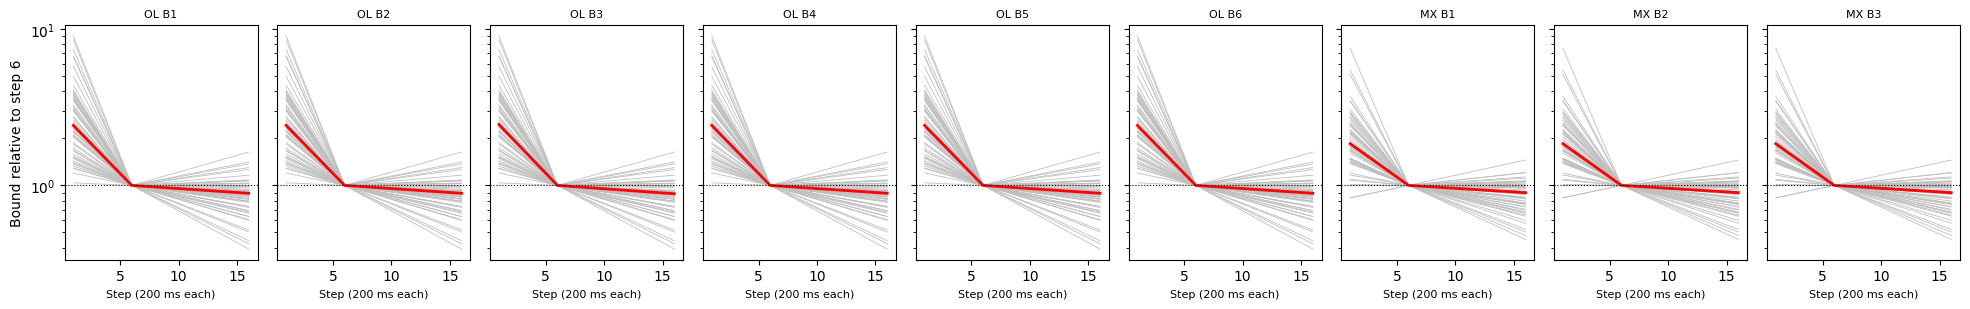

In [5]:
steps_ax = np.arange(1, 17)
conds = [(task, c) for task, d in tables.items() for c in sorted(d.condition.unique())]
fig, axes = plt.subplots(1, len(conds), figsize=(2.2 * len(conds), 3.2), sharey=True)
for ax, (task, c) in zip(axes, conds):
    s = fits[(fits.task == task) & (fits.group == c)]
    curves = np.array([bound_time_course({**row, 'bound_scale': 1.0}, steps_ax) for _, row in s.iterrows()])
    ax.plot(steps_ax, curves.T, color='0.75', lw=0.6)
    ax.plot(steps_ax, np.median(curves, axis=0), 'r-', lw=2)
    ax.axhline(1, color='k', ls=':', lw=0.8)
    ax.set_title(f'{task} {c}', fontsize=8)
    ax.set_xlabel('Step (200 ms each)', fontsize=8)
axes[0].set_ylabel('Bound relative to step 6')
axes[0].set_yscale('log')
plt.tight_layout()
plt.show()

### Model comparison across variants

Total negative log-likelihood and AIC (summed over subjects) per dataset. Lower
is better; AIC penalizes each free parameter by 2. AIC is a rough guide here
(the variants differ in flexibility in ways AIC handles imperfectly); held-out
likelihood is the planned check.

**Note (2026-10-10):** the main fit was redone with anticipations as RT = 1 only;
the other variants still use the earlier definition (anticipations spread over
the first NDT + 1 frames), so their ΔAIC here is inflated until they are refit.
With the old definition throughout, the ordering was the same (see the round-2
interpretation below).

In [6]:
comp = []
for v, f in fits_all.items():
    s = f.groupby(['task', 'subject_index']).first()
    for task, g in s.groupby(level=0):
        comp.append({'variant': v, 'task': task, 'subjects': len(g), 'NLL': g.nll.sum(),
                     'AIC': (2 * g.nll + 2 * g.n_params).sum(), 'params / subject': g.n_params.median()})
comp = pd.DataFrame(comp)
comp['ΔAIC vs main'] = comp.AIC - comp.task.map(comp[comp.variant == 'main'].set_index('task').AIC)
comp.sort_values(['task', 'AIC']).round(1)

,variant,task,subjects,NLL,AIC,params / subject,ΔAIC vs main
0,main,MX,60,27326.8,56933.7,19.0,0.0
10,no_noise,MX,60,28258.1,58676.3,18.0,1742.6
8,ndt123,MX,60,28171.2,58742.4,20.0,1808.8
2,per_block_tc,MX,60,28028.3,58816.5,23.0,1882.8
6,shared_rates,MX,60,28932.7,59425.4,13.0,2491.7
4,flat,MX,60,28860.5,59761.0,17.0,2827.3
1,main,OL,60,60231.1,124532.2,34.0,0.0
9,ndt123,OL,60,62489.3,129168.5,35.0,4636.3
3,per_block_tc,OL,60,62314.2,129894.5,44.0,5362.2
11,no_noise,OL,60,63017.4,129984.7,33.0,5452.5


### Does the model describe the data? (posterior predictive checks)

Each subject is simulated from their own fitted parameters, five times over their
real trials (same condition, step statistics and trial count). Real (black) vs.
model (red), pooled over subjects.

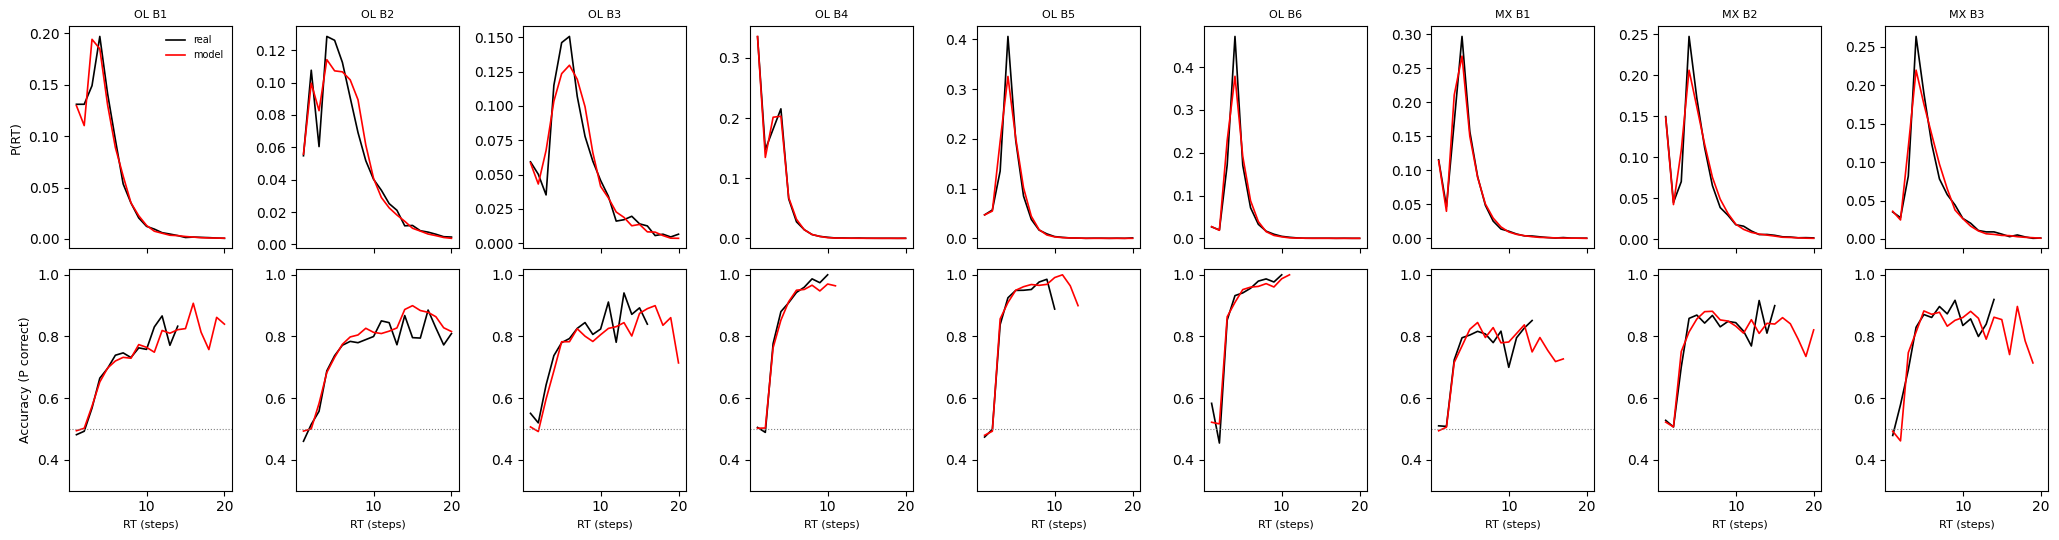

In [7]:
PPC_SEED = 11
PPC_REPS = 5
sims = {task: simulate_stopping_data_table(d, fits[fits.task == task], group_col='condition',
                                           num_reps=PPC_REPS, rng=np.random.default_rng(PPC_SEED))
        for task, d in tables.items()}

MAX_RT_SHOW = 20
rt_ax = np.arange(1, MAX_RT_SHOW + 1)
fig, axes = plt.subplots(2, len(conds), figsize=(2.3 * len(conds), 5.5), sharex=True)
for ci, (task, c) in enumerate(conds):
    real = tables[task][tables[task].condition == c]
    sim = sims[task][sims[task].condition == c]
    for t, col in ((real, 'k'), (sim, 'r')):
        axes[0, ci].plot(rt_ax, t.RT.value_counts(normalize=True).reindex(rt_ax, fill_value=0), '-', color=col, lw=1.2)
        acc = t.groupby('RT').correct.agg(['mean', 'size']).reindex(rt_ax)
        acc.loc[acc['size'] < 20, 'mean'] = np.nan
        axes[1, ci].plot(rt_ax, acc['mean'], '-', color=col, lw=1.2)
    axes[0, ci].set_title(f'{task} {c}', fontsize=8)
    axes[1, ci].axhline(0.5, color='gray', ls=':', lw=0.8)
    axes[1, ci].set_ylim(0.3, 1.02)
    axes[1, ci].set_xlabel('RT (steps)', fontsize=8)
axes[0, 0].set_ylabel('P(RT)', fontsize=9)
axes[1, 0].set_ylabel('Accuracy (P correct)', fontsize=9)
axes[0, 0].legend(['real', 'model'], fontsize=7, frameon=False)
plt.tight_layout()
plt.show()

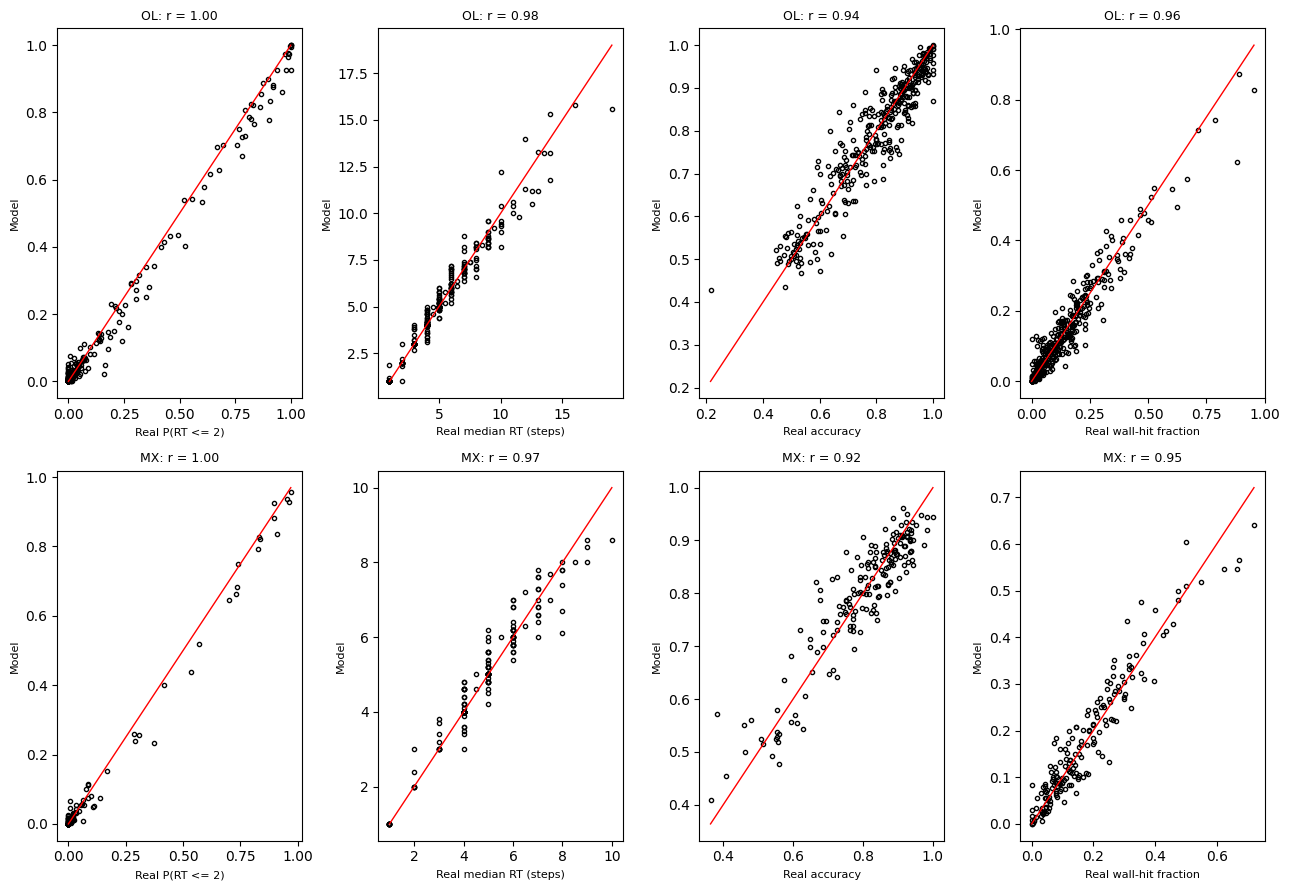

,task,statistic,r,mean real,mean model
0,OL,P(RT <= 2),0.996,0.129,0.124
1,OL,median RT (steps),0.982,5.056,5.066
2,OL,accuracy,0.942,0.791,0.788
3,OL,wall-hit fraction,0.963,0.147,0.146
4,MX,P(RT <= 2),0.996,0.087,0.083
5,MX,median RT (steps),0.968,4.822,4.863
6,MX,accuracy,0.921,0.797,0.796
7,MX,wall-hit fraction,0.955,0.174,0.178


In [8]:
def _subject_stats(t):
    g = t.groupby(['subject_index', 'condition'])
    return pd.DataFrame({'P(RT <= 2)': g.RT.apply(lambda r: np.mean(r <= 2)),
                         'median RT (steps)': g.RT.median(),
                         'accuracy': g.correct.mean(),
                         'wall-hit fraction': g.wall_hit.mean()})

STAT_NAMES = ['P(RT <= 2)', 'median RT (steps)', 'accuracy', 'wall-hit fraction']
fig, axes = plt.subplots(len(DATASETS), len(STAT_NAMES), figsize=(13, 9))
ppc_rows = []
for ti, task in enumerate(DATASETS):
    real = _subject_stats(tables[task])
    sim = sims[task].groupby('rep').apply(_subject_stats).groupby(level=[1, 2]).mean()
    both = real.join(sim, rsuffix=' model')
    for si, s in enumerate(STAT_NAMES):
        ax = axes[ti, si]
        ax.plot(both[s], both[f'{s} model'], 'o', mfc='none', color='k', ms=3)
        lims = [np.nanmin(both[[s, f'{s} model']].values), np.nanmax(both[[s, f'{s} model']].values)]
        ax.plot(lims, lims, 'r-', lw=1)
        rr = both[[s, f'{s} model']].corr().iloc[0, 1]
        ax.set_title(f'{task}: r = {rr:.2f}', fontsize=9)
        ax.set_xlabel(f'Real {s}', fontsize=8)
        ax.set_ylabel('Model', fontsize=8)
        ppc_rows.append({'task': task, 'statistic': s, 'r': rr,
                         'mean real': np.nanmean(both[s]), 'mean model': np.nanmean(both[f'{s} model'])})
plt.tight_layout()
plt.show()
pd.DataFrame(ppc_rows).round(3)

### Figure03S03's statistics: incongruence and premature crossings

The same definitions as Figure03S03 (`pigeon.data.get_crossing_diagnostics`),
computed on real data and on the model's simulated data after running both
through the real-data bound pipeline (`get_bounds` per subject; trials passing
`get_good_trial_array`: DT ≥ 2, trial_number ≥ 10, not a wall hit). Binned by
the inferred |bound| (0.1 wide). Per-subject bin means (≥ 5 trials), then mean ± SEM across
subjects (≥ 3 subjects). Figure03S03's fixed-bound scenarios could not reproduce
the incongruence floor at large bounds, or premature crossings with plausible NDTs.

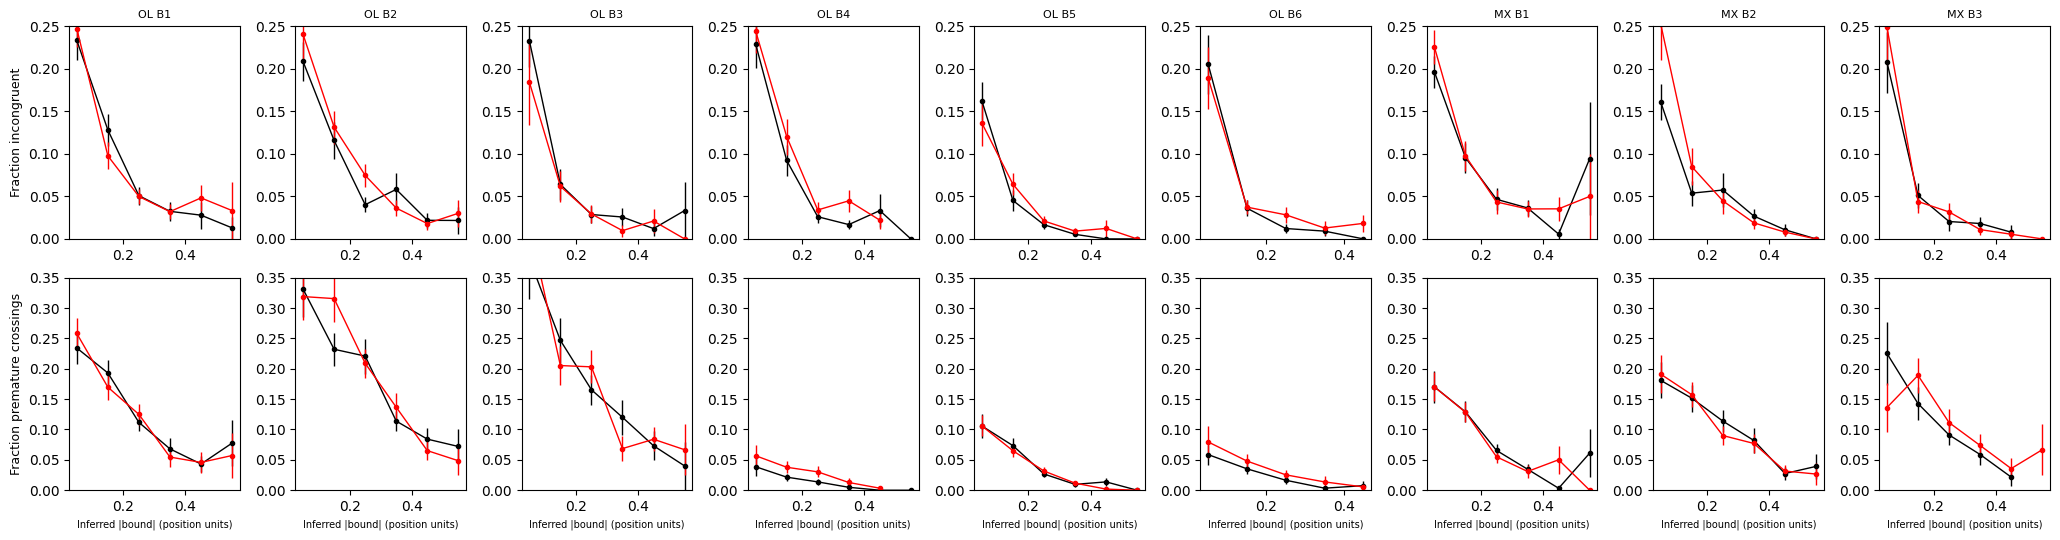

In [9]:
BIN_WIDTH = {'OL': 0.1, 'MX': 0.1}

def _diagnostics(t):
    t = t[get_good_trial_array(t, min_dt=2, min_trial_number=10)].copy()
    t[['incongruent', 'premature_crossing']] = get_crossing_diagnostics(t).values
    return t

def _binned(t, col, width, min_trials=5, min_subj=3):
    t = t.assign(_bin=np.floor(t.abs_bound / width))
    per_subj = t.groupby(['subject_index', '_bin'])[col].agg(['mean', 'size'])
    per_subj = per_subj[per_subj['size'] >= min_trials]['mean']
    g = per_subj.groupby(level='_bin').agg(['mean', 'sem', 'size'])
    g = g[g['size'] >= min_subj]
    return (g.index.to_numpy() + 0.5) * width, g['mean'].to_numpy(), g['sem'].to_numpy()

diag_real = {task: _diagnostics(d) for task, d in tables.items()}
diag_sim = {task: _diagnostics(infer_bounds_like_data(s[s.rep == 0]).assign(trial_number=99))
            for task, s in sims.items()}

fig, axes = plt.subplots(2, len(conds), figsize=(2.3 * len(conds), 5.5))
for ci, (task, c) in enumerate(conds):
    for ri, col in enumerate(('incongruent', 'premature_crossing')):
        ax = axes[ri, ci]
        for t, color in ((diag_real[task], 'k'), (diag_sim[task], 'r')):
            x, y, e = _binned(t[t.condition == c], col, BIN_WIDTH[task])
            ax.errorbar(x, y, yerr=e, fmt='o-', color=color, ms=3, lw=1, capsize=0)
        ax.set_ylim(0, 0.35 if ri else 0.25)
        if ri == 0:
            ax.set_title(f'{task} {c}', fontsize=8)
        else:
            ax.set_xlabel('Inferred |bound| (position units)', fontsize=7)
axes[0, 0].set_ylabel('Fraction incongruent', fontsize=9)
axes[1, 0].set_ylabel('Fraction premature crossings', fontsize=9)
plt.tight_layout()
plt.show()

### How many guesses survive the standard DT ≥ 2 filter?

In the simulated data each commit's source is known (bound crossing, guess or
anticipation). After the real-data bound pipeline and the paper's filter
(`get_good_trial_array`), what fraction of the surviving trials are guesses or
anticipations?

In [10]:
guess_rows = []
for task, s in sims.items():
    t = infer_bounds_like_data(s[s.rep == 0]).assign(trial_number=99)
    l_pass = get_good_trial_array(t, min_dt=2, min_trial_number=10)
    for c, tc in t.groupby('condition'):
        lp = l_pass.loc[tc.index]
        nonbound = tc.commit_type.isin(['guess', 'anticipation'])
        guess_rows.append({'task': task, 'condition': c,
                           'guess + anticipation, all trials': nonbound.mean(),
                           'guess + anticipation, passing filter': nonbound[lp].mean(),
                           'lapse, passing filter': tc.lapse[lp].mean(),
                           'fraction of trials passing': lp.mean()})
pd.DataFrame(guess_rows).round(3)

,task,condition,"guess + anticipation, all trials","guess + anticipation, passing filter","lapse, passing filter",fraction of trials passing
0,OL,B1,0.435,0.121,0.107,0.457
1,OL,B2,0.254,0.084,0.099,0.623
2,OL,B3,0.166,0.044,0.050,0.693
3,OL,B4,0.543,0.079,0.053,0.194
4,OL,B5,0.128,0.012,0.021,0.433
5,OL,B6,0.063,0.009,0.020,0.450
6,MX,B1,0.232,0.051,0.072,0.457
7,MX,B2,0.241,0.038,0.056,0.479
8,MX,B3,0.115,0.038,0.039,0.565


### Fitted bounds vs. the paper's median |bound|

How well do the fitted bounds match the per-subject bound summaries used so far,
and is either version of those summaries (raw or bias-corrected) biased relative
to the model? `pigeon.stopping.get_fit_vs_median_bounds` computes, per subject
and block:

- **median |bound|**: over the paper's standard trial set (`get_good_trial_array`:
  DT ≥ 2, trial_number ≥ 10, no wall hit, RT cutoff), raw and after
  `apply_bias_corrections` (`boundBiasCorrection.mat`);
- **effective fitted bound**: the model's mean bound at each trial's commit step
  (`RT − NDT − 1`, averaged over the fitted NDT), averaged over the same trials,
  so it weights the time course by when that subject responded.

The same is done on data simulated from the fits (three sessions per subject),
where the true bound is known. That gives the agreement to expect if the model
were exactly right, and shows whether the median method is biased under the
model.

In [11]:
from pigeon.data import get_data_table
from pigeon.pathDefaults import BIAS_CORRECTION_FILE
from pigeon.stopping import get_fit_vs_median_bounds

FVM_SEED = 20261010
FVM_REPS = 3
fvm_real, fvm_sim = {}, {}
for task, blocks in DATASETS.items():
    raw = get_data_table(task_type=task, combine_snr=False, correct_bias=None)
    raw = raw[raw.block_index.isin(blocks)].copy()
    raw['condition'] = [f'B{b:.0f}' for b in raw.block_index]
    f_task = fits[fits.task == task]
    fvm_real[task] = get_fit_vs_median_bounds(raw, f_task, BIAS_CORRECTION_FILE)

    # Simulated sessions: each rep is its own subject-session, fit by the true parameters.
    sim = simulate_stopping_data_table(tables[task], f_task, group_col='condition', num_reps=FVM_REPS,
                                       rng=np.random.default_rng(FVM_SEED))
    sim = infer_bounds_like_data(sim).assign(trial_number=99)
    sim['subject_index'] = sim.subject_index * 10 + sim.rep
    f_rep = pd.concat([f_task.assign(subject_index=f_task.subject_index * 10 + r) for r in range(FVM_REPS)])
    fvm_sim[task] = get_fit_vs_median_bounds(sim, f_rep, BIAS_CORRECTION_FILE)

In [12]:
import scipy.stats

FVM_BOOT = 2000

def _rho_ci(x, y, rng):
    """Spearman r with a 95% bootstrap CI (resampling subjects)."""
    idx = rng.integers(0, len(x), (FVM_BOOT, len(x)))
    boot = [scipy.stats.spearmanr(x[i], y[i])[0] for i in idx]
    lo, hi = np.nanpercentile(boot, [2.5, 97.5])
    return f'{scipy.stats.spearmanr(x, y)[0]:.2f} [{lo:.2f}, {hi:.2f}]'

rng_boot = np.random.default_rng(FVM_SEED)
fvm_rows = []
for task in DATASETS:
    for source, tab in (('real', fvm_real[task]), ('simulated', fvm_sim[task])):
        for c, g in tab.dropna().groupby('group'):
            row = {'task': task, 'block': c, 'data': source, 'n subjects': len(g)}
            for med in ('median_raw', 'median_corrected'):
                row[f'r: fit vs {med}'] = _rho_ci(g.effective_bound.to_numpy(), g[med].to_numpy(), rng_boot)
            for med in ('median_raw', 'median_corrected'):
                row[f'{med} / fit'] = np.median(g[med] / g.effective_bound)
            row['r: bound_scale vs median_corrected'] = _rho_ci(g.bound_scale.to_numpy(),
                                                                g.median_corrected.to_numpy(), rng_boot)
            fvm_rows.append(row)
pd.DataFrame(fvm_rows).set_index(['task', 'block', 'data']).sort_index(level=[0, 2, 1]).round(2)

n subjects r: fit vs median_raw  \
task block data                                         
MX   B1    real               60    0.62 [0.41, 0.77]   
     B2    real               59    0.58 [0.35, 0.76]   
     B3    real               59    0.61 [0.34, 0.81]   
     B1    simulated         180    0.61 [0.47, 0.73]   
     B2    simulated         179    0.56 [0.40, 0.70]   
     B3    simulated         168    0.61 [0.46, 0.74]   
OL   B1    real               59    0.55 [0.34, 0.72]   
     B2    real               60    0.52 [0.22, 0.77]   
     B3    real               55    0.77 [0.64, 0.85]   
     B4    real               56    0.39 [0.15, 0.61]   
     B5    real               58    0.49 [0.25, 0.70]   
     B6    real               52    0.56 [0.27, 0.74]   
     B1    simulated         179    0.47 [0.32, 0.61]   
     B2    simulated         179    0.55 [0.41, 0.67]   
     B3    simulated         166    0.66 [0.52, 0.77]   
     B4    simulated         170    0.37 [0.21, 0.50]   
     B5    simulated         179    0.46 [0.30, 0.60]   
     B6    simulated         161    0.65 [0.53, 0.75]   

                     r: fit vs median_corrected  median_raw / fit  \
task block data                                                     
MX   B1    real               0.60 [0.39, 0.76]              1.01   
     B2    real               0.57 [0.35, 0.74]              0.89   
     B3    real               0.60 [0.35, 0.82]              0.94   
     B1    simulated          0.61 [0.48, 0.73]              1.11   
     B2    simulated          0.56 [0.41, 0.70]              1.01   
     B3    simulated          0.61 [0.46, 0.74]              1.08   
OL   B1    real               0.58 [0.38, 0.76]              0.87   
     B2    real               0.52 [0.22, 0.76]              0.85   
     B3    real               0.78 [0.63, 0.86]              0.85   
     B4    real               0.38 [0.12, 0.59]              1.55   
     B5    real               0.48 [0.24, 0.68]              1.09   
     B6    real               0.55 [0.28, 0.74]              1.46   
     B1    simulated          0.47 [0.33, 0.61]              0.89   
     B2    simulated          0.55 [0.41, 0.68]              0.84   
     B3    simulated          0.66 [0.51, 0.77]              0.87   
     B4    simulated          0.37 [0.23, 0.50]              1.55   
     B5    simulated          0.45 [0.30, 0.58]              1.16   
     B6    simulated          0.65 [0.53, 0.74]              1.53   

                      median_corrected / fit  \
task block data                                
MX   B1    real                         0.95   
     B2    real                         0.90   
     B3    real                         0.93   
     B1    simulated                    1.07   
     B2    simulated                    1.00   
     B3    simulated                    1.05   
OL   B1    real                         0.89   
     B2    real                         0.87   
     B3    real                         0.87   
     B4    real                         1.25   
     B5    real                         1.02   
     B6    real                         1.23   
     B1    simulated                    0.89   
     B2    simulated                    0.86   
     B3    simulated                    0.89   
     B4    simulated                    1.38   
     B5    simulated                    1.05   
     B6    simulated                    1.33   

                     r: bound_scale vs median_corrected  
task block data                                          
MX   B1    real                       0.49 [0.26, 0.68]  
     B2    real                       0.47 [0.26, 0.67]  
     B3    real                       0.56 [0.28, 0.77]  
     B1    simulated                  0.54 [0.40, 0.67]  
     B2    simulated                  0.49 [0.34, 0.63]  
     B3    simulated                  0.57 [0.42, 0.70]  
OL   B1    real                       0.58 [0.36, 0.76]  
     B2    real  

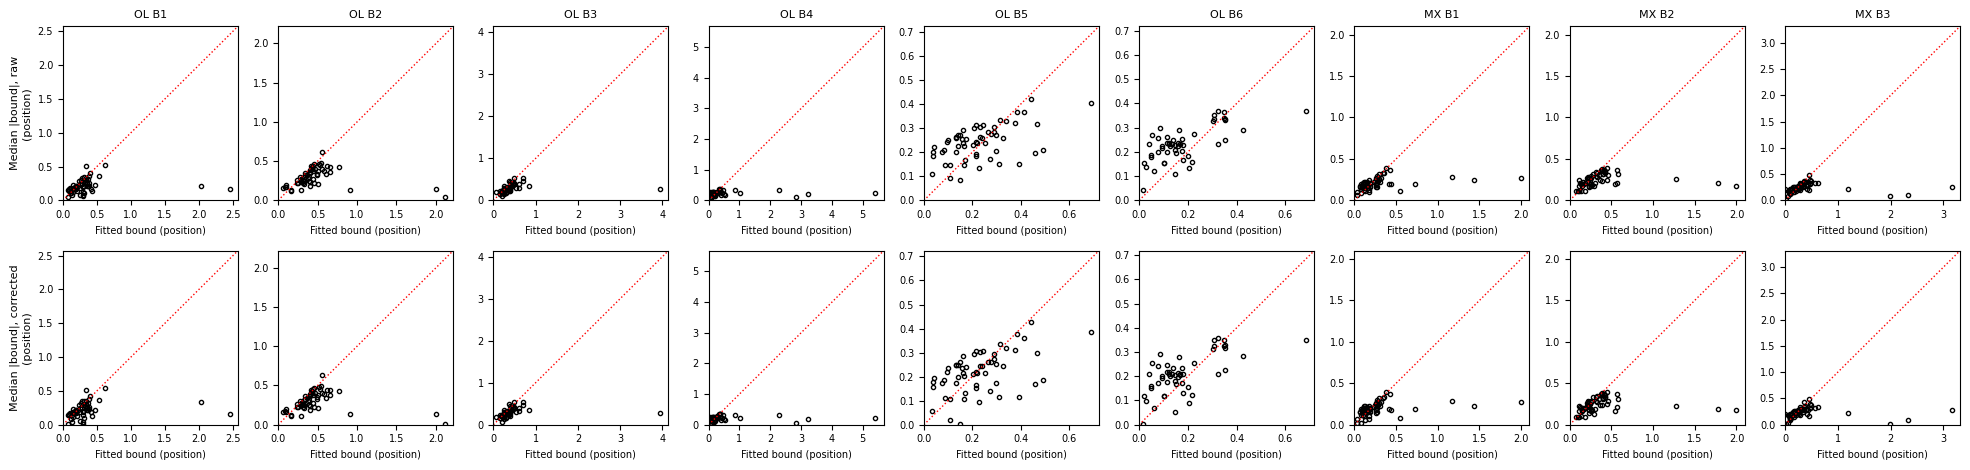

In [13]:
fig, axes = plt.subplots(2, len(conds), figsize=(2.2 * len(conds), 4.8))
for ci, (task, c) in enumerate(conds):
    g = fvm_real[task][fvm_real[task].group == c].dropna()
    for ri, med in enumerate(('median_raw', 'median_corrected')):
        ax = axes[ri, ci]
        ax.plot(g.effective_bound, g[med], 'o', mfc='none', color='k', ms=3)
        top = max(g.effective_bound.max(), g[med].max()) * 1.05
        ax.plot([0, top], [0, top], 'r:', lw=1)
        ax.set_xlim(0, top)
        ax.set_ylim(0, top)
        if ri == 0:
            ax.set_title(f'{task} {c}', fontsize=8)
        ax.set_xlabel('Fitted bound (position)', fontsize=7)
        ax.tick_params(labelsize=7)
axes[0, 0].set_ylabel('Median |bound|, raw\n(position)', fontsize=8)
axes[1, 0].set_ylabel('Median |bound|, corrected\n(position)', fontsize=8)
plt.tight_layout()
plt.show()

**Fitted vs. median bounds (2026-10-10).**

- **Ranking:** Spearman r between fitted and median bounds is moderate, about
  0.4–0.8 per block. On data simulated from the fits, where the model is true by
  construction, the median bound correlates with the true bound about as well
  (≈0.35–0.7). So the moderate agreement reflects how noisy the median bound is
  as a per-subject estimate (30–150 trials per block, mostly short DTs), not a
  disagreement between the fits and the medians.
- **Bias correction and correlation:** almost no effect; it rescales bounds
  within each DT × SNR bin nearly monotonically, so subjects' ranks barely move.
- **Level:** at low SNR (OL B1–B3) the median bound is ~13–15% below the fitted
  bound, raw or corrected. At high SNR (OL B4, B6) it is ~50% above raw and ~25%
  above after correction. MX is close to unbiased (0.9–1.0). The simulations
  reproduce these ratios closely (high-SNR OL corrected: 1.3–1.4; MX 1.0–1.1), so this is a bias of the median method
  under the model (the current correction ignores guesses and the early bound
  collapse), not a disagreement in the data. It implies that median-based
  high- vs. low-SNR bound comparisons in OL are exaggerated.
- **Do the fits need their own correction?** Not expected: overshoot, NDT,
  guesses and wall hits are in the likelihood, and recovery gives r = 0.94–0.99
  for `bound_scale`. The parametric bootstrap (`scripts/run_stopping_bootstrap.py`)
  checks fitted-vs-true bias at each subject's own parameters.

### Interpretation (2026-10-10, round 3: anticipations at RT = 1 only)

- **Anticipation definition:** making anticipations first-frame presses only
  (and allowing guesses at step 0) improves the total NLL by 2,244 (OL) and 752
  (MX) with the same number of parameters, and removes the RT = 1 vs. 2 misfit:
  simulated RT = 1 and 2 fractions now match the data in every block (e.g. OL B4
  0.336 / 0.134 simulated vs. 0.335 / 0.147 real; previously 0.503 / 0.078).
  Remaining misfit: the model puts slightly too many responses at RT = 3 and too
  few at RT = 4 in OL B5/B6 and MX.
- **Fit quality:** per-subject P(RT ≤ 2), median RT, accuracy and wall-hit rate
  are reproduced (r = 0.92–1.0).
- **Bound time course:** the bound is ~2.4× (OL) / ~1.8× (MX) higher at step 1
  than at step 6, then ~11% lower by step 16.
- **Guesses, anticipations, lapses:** concentrated in OL B1, B4 and MX B1. After
  the paper's filter (DT ≥ 2, no wall hits, trial_number ≥ 10), simulated trials
  are 1–12% guesses or anticipations and 2–11% lapses, depending on block (round
  2: 9–23% and 2–15%).
- **Noise vs. guesses:** with the new definition, sensory noise roughly doubled
  (OL 0.04 → 0.09, MX 0.05 → 0.08) while guess rates fell to near zero in most
  blocks; bound levels barely moved. The noise / bound CV / guess split is not
  well pinned down; the parametric bootstrap tests it at each subject's own
  parameters.

### Interpretation (2026-10-10, round 2)

- **Model comparison (AIC, summed over subjects):** the main model (bound scale,
  CV and the three rates per block; time course, noise and NDT shared) is best in
  both datasets. Next best: NDT 1–3 (+148 OL, +304 MX), per-block time courses
  (+874, +378), no sensory noise (+964, +238), constant bound (+3,097, +1,322),
  shared rates (+12,068, +987).
- **Fit quality:** per-subject statistics and Figure03S03's incongruence and
  premature-crossing curves were matched in all OL and MX blocks with NDT ≤ 2;
  RT = 1 was over- and RT = 2 under-predicted (fixed in round 3).
- **Guesses:** 9–23% guesses or anticipations and 2–15% lapses after the paper's
  filter; sensory noise ~0.04, bound CV ~0.4.